In [1]:
import os

import glob

import numpy as np
import pandas as pd
import xarray as xr

In [2]:
# BASE_DATA_PATH = "/nfs-lncc/users/ajosemf/rionowcast/datalake/staged/radar/inea/guaratiba"
BASE_DATA_PATH = "/home/mauro/Documents/Landing/"

In [3]:
folders = glob.glob(os.path.join(BASE_DATA_PATH, "*"))
print(f"There are {len(folders)} folders")

There are 1 folders


In [4]:
year = "2016"
print(f"Selecting only {year} folders")
folders = [f for f in folders if f.split("/")[-1].startswith(year)]
print(f"There are {len(folders)} folders for {year}")

Selecting only 2016 folders
There are 1 folders for 2016


In [5]:
index = 0
print(f"Selecting folder {index} of {len(folders)}")
folder = folders[index]
groups = glob.glob(os.path.join(folder, "*"))
print(f"There are {len(groups)} groups in {folder}")

Selecting folder 0 of 1
There are 9 groups in /home/mauro/Documents/Landing/2016-09-19


In [6]:
zarr_file = groups[0]
ds = xr.open_zarr(zarr_file)

/tmp/ipykernel_4990/1048913257.py:2: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  ds = xr.open_zarr(zarr_file)


In [7]:
# groups_list = []
# for zarr_file in groups:
#     groups_list.append(xr.open_zarr(zarr_file))

# print(f"Variables in the first group: {groups_list[0]}")
# print("Done")

In [8]:
# ds = xr.concat(groups_list, dim="obs") # 30min +

In [9]:
# ds = xr.open_mfdataset(groups, combine="by_coords", engine="zarr", parallel=True)

In [10]:
ds.data_vars

Data variables:
    dbzv       (obs) float64 131MB ...
    phidp      (obs) float64 131MB ...
    altitude   (obs) float64 131MB ...
    rhohv      (obs) float64 131MB ...
    snr        (obs) float64 131MB ...
    datetime   (obs) datetime64[ns] 131MB ...
    latitude   (obs) float64 131MB ...
    zdr        (obs) float64 131MB ...
    dbzh       (obs) float64 131MB ...
    sqi        (obs) float64 131MB ...
    tv         (obs) float64 131MB ...
    th         (obs) float64 131MB ...
    longitude  (obs) float64 131MB ...
    wrad       (obs) float64 131MB ...
    vrad       (obs) float64 131MB ...

In [11]:
d = {
    "dbzh": np.array(ds["dbzh"]),
    "lat": np.array(ds["latitude"]),
    "lon": np.array(ds["longitude"]),
    "time": np.array(ds["datetime"]),
    "altitude": np.array(ds["altitude"]),
}

In [12]:
df = pd.DataFrame(d)

In [13]:
df

,dbzh,lat,lon,time,altitude
0,0.0,-22.99099,-43.58792,2016-09-19 14:30:16,122.2
1,0.0,-22.98648,-43.58787,2016-09-19 14:30:16,126.6
2,0.0,-22.98196,-43.58782,2016-09-19 14:30:16,131.0
3,0.0,-22.97745,-43.58777,2016-09-19 14:30:16,135.4
4,0.0,-22.97293,-43.58772,2016-09-19 14:30:16,139.9
...,...,...,...,...,...
16377495,0.0,-21.95352,-43.60157,2016-09-19 12:37:58,41880.0
16377496,0.0,-21.94930,-43.60162,2016-09-19 12:37:58,42053.3
16377497,0.0,-21.94509,-43.60167,2016-09-19 12:37:58,42226.6
16377498,0.0,-21.94088,-43.60173,2016-09-19 12:37:58,42400.0


In [14]:
df.shape

(16377500, 5)

In [15]:
last_len_altitude = 0
last_id_altitude = 0
diff_len_altitude = []
times = df["time"].unique()
for i in range(len(times)):
    df_filtered = df[df["time"] == times[i]]
    altitude = df_filtered["altitude"].max()
    if altitude > last_len_altitude:
        last_len_altitude = altitude
        last_id_altitude = i
    if altitude not in diff_len_altitude:
        diff_len_altitude.append(altitude)

print(f"There were {len(diff_len_altitude)} different altitudes")

There were 14 different altitudes


In [16]:
display(times[0])
display(times[last_id_altitude])

Timestamp('2016-09-19 14:30:16')

Timestamp('2016-09-19 14:37:58')

In [17]:
display(df[df["time"] == times[0]]["altitude"].unique())
display(df[df["time"] == times[last_id_altitude]]["altitude"].unique())

array([ 122.2,  126.6,  131. ,  135.4,  139.9,  144.4,  149. ,  153.5,
        158.1,  162.8,  167.4,  172.1,  176.8,  181.6,  186.3,  191.1,
        196. ,  200.8,  205.7,  210.7,  215.6,  220.6,  225.6,  230.6,
        235.7,  240.8,  245.9,  251.1,  256.3,  261.5,  266.7,  272. ,
        277.3,  282.6,  288. ,  293.4,  298.8,  304.3,  309.7,  315.2,
        320.8,  326.4,  332. ,  337.6,  343.2,  348.9,  354.6,  360.4,
        366.2,  372. ,  377.8,  383.7,  389.5,  395.5,  401.4,  407.4,
        413.4,  419.4,  425.5,  431.6,  437.7,  443.9,  450.1,  456.3,
        462.5,  468.8,  475.1,  481.4,  487.8,  494.2,  500.6,  507.1,
        513.5,  520.1,  526.6,  533.2,  539.8,  546.4,  553. ,  559.7,
        566.4,  573.2,  580. ,  586.8,  593.6,  600.5,  607.3,  614.3,
        621.2,  628.2,  635.2,  642.2,  649.3,  656.4,  663.5,  670.7,
        677.9,  685.1,  692.3,  699.6,  706.9,  714.2,  721.6,  729. ,
        736.4,  743.9,  751.3,  758.9,  766.4,  774. ,  781.6,  789.2,
      

array([  203.5,   370.4,   537.4,   704.3,   871.4,  1038.4,  1205.5,
        1372.6,  1539.7,  1706.8,  1874. ,  2041.2,  2208.4,  2375.7,
        2542.9,  2710.2,  2877.6,  3044.9,  3212.3,  3379.7,  3547.1,
        3714.6,  3882.1,  4049.6,  4217.1,  4384.7,  4552.3,  4719.9,
        4887.5,  5055.2,  5222.9,  5390.6,  5558.4,  5726.1,  5893.9,
        6061.7,  6229.6,  6397.5,  6565.4,  6733.3,  6901.2,  7069.2,
        7237.2,  7405.3,  7573.3,  7741.4,  7909.5,  8077.7,  8245.8,
        8414. ,  8582.2,  8750.5,  8918.7,  9087. ,  9255.3,  9423.7,
        9592.1,  9760.4,  9928.9, 10097.3, 10265.8, 10434.3, 10602.8,
       10771.4, 10940. , 11108.6, 11277.2, 11445.8, 11614.5, 11783.2,
       11952. , 12120.7, 12289.5, 12458.3, 12627.2, 12796. , 12964.9,
       13133.8, 13302.8, 13471.8, 13640.8, 13809.8, 13978.8, 14147.9,
       14317. , 14486.1, 14655.3, 14824.5, 14993.7, 15162.9, 15332.1,
       15501.4, 15670.7, 15840.1, 16009.4, 16178.8, 16348.2, 16517.7,
       16687.1, 1685

In [18]:
diff_len_altitude

[np.float64(2123.6),
 np.float64(4299.2),
 np.float64(6258.3),
 np.float64(8323.1),
 np.float64(10385.3),
 np.float64(12444.5),
 np.float64(14500.1),
 np.float64(17297.3),
 np.float64(19884.8),
 np.float64(22662.9),
 np.float64(26935.6),
 np.float64(31162.9),
 np.float64(36802.9),
 np.float64(42573.3)]

In [19]:
df["altitude"].nunique()

3470

In [21]:
import matplotlib.pyplot as plt

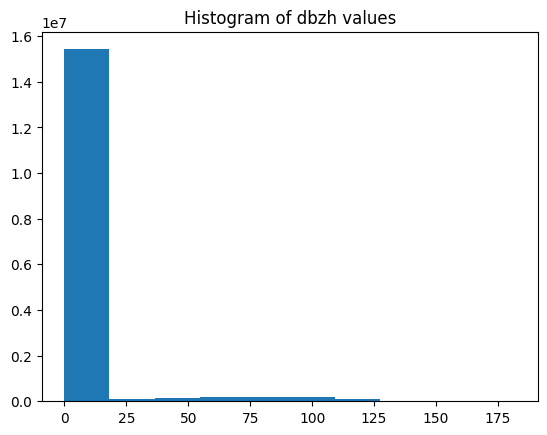

In [22]:
plt.hist(df["dbzh"])
plt.title("Histogram of dbzh values")
plt.show()

In [23]:
df["dbzh"].describe()

count    1.637750e+07
mean     4.365187e+00
std      1.859414e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.820000e+02
Name: dbzh, dtype: float64

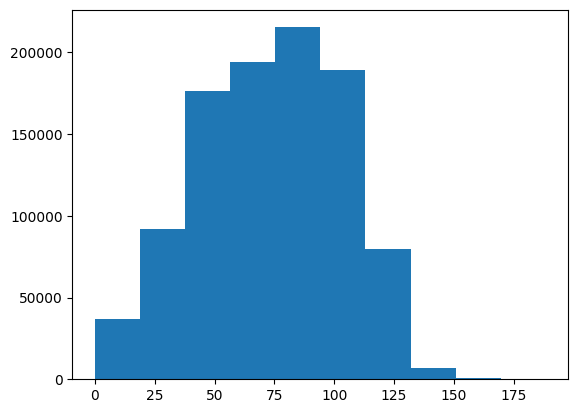

In [24]:
from scipy import stats

original_data = df["dbzh"][df["dbzh"] > 0]
fitted_data, fitted_lambda = stats.boxcox(original_data)

plt.hist(fitted_data)
plt.show()

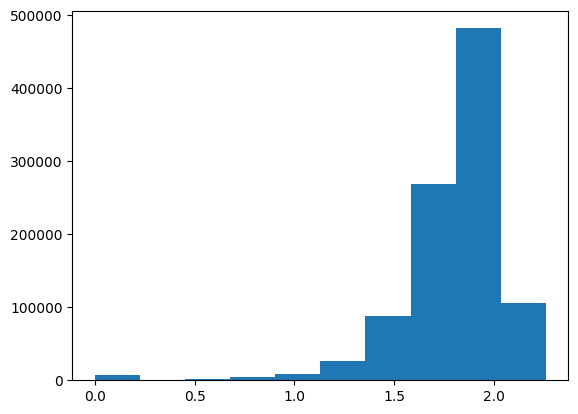

In [25]:
# plt.hist(np.log10(df["dbzh"] + 1e-6))
plt.hist(np.log10(original_data))
plt.show()

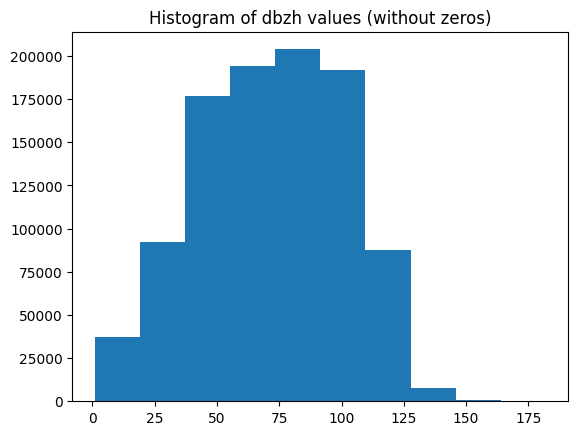

In [26]:
plt.hist(df["dbzh"][df["dbzh"] > 0])
plt.title("Histogram of dbzh values (without zeros)")
plt.show()

In [27]:
print(f"{df['lat'].nunique()} unique latitudes {df['lon'].nunique()} unique longitudes")

198264 unique latitudes 230757 unique longitudes


In [28]:
lat_lons = [val for val in zip(df["lat"], df["lon"])]

In [29]:
lat_lons_np = np.array(lat_lons)

In [30]:
unique_lat_lons = np.unique(lat_lons_np, axis=0)
# unique_lat_lons_index = np.unique(lat_lons_np, return_index=True, axis=0)

In [31]:
print(len(unique_lat_lons), "unique lat/lon pairs")

1698507 unique lat/lon pairs


In [32]:
unique_lat_lons

array([[-24.11936, -43.58794],
       [-24.1193 , -43.60045],
       [-24.1193 , -43.57543],
       ...,
       [-21.86704, -43.60021],
       [-21.86704, -43.57567],
       [-21.86704, -43.57563]], shape=(1698507, 2))

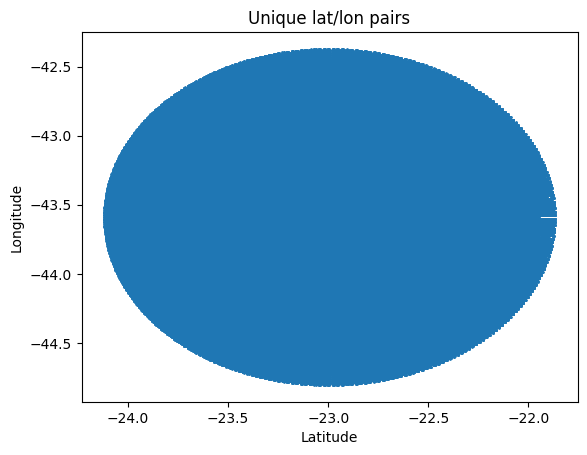

In [33]:
x = [val[0] for val in unique_lat_lons]
y = [val[1] for val in unique_lat_lons]

plt.scatter(x, y, s=1)
plt.title("Unique lat/lon pairs")
plt.xlabel("Latitude")
plt.ylabel("Longitude")
plt.show()

In [34]:
x = np.array(x)
y = np.array(y)

ValueError: x and y must be the same size

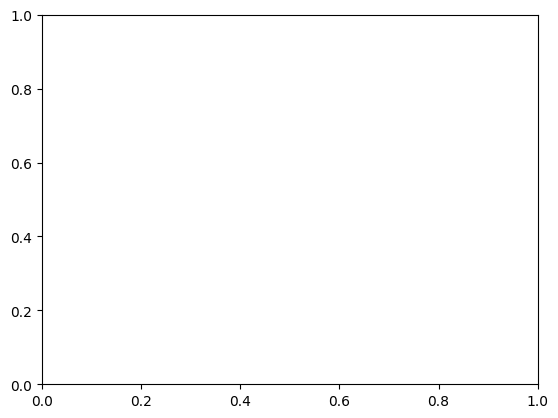

In [35]:
x_slice = x[np.where(x > -21) and np.where(x < -25)]
y_slice = y[np.where(y > -46) and np.where(y < -42)]

plt.scatter(x_slice, y_slice, s=1)
plt.title("Unique lat/lon pairs")
plt.xlabel("Latitude")
plt.ylabel("Longitude")
plt.show()

In [ ]:
import folium

m = folium.Map(location=[np.mean(df["lat"]), np.mean(df["lon"])], zoom_start=10)

folium.Marker(
    location=[np.mean(df["lat"]), np.mean(df["lon"])],
    popup="Radar Location",
).add_to(m)

# folium.Marker(
#     location=[np.min(df["lat"]), np.min(df["lon"])],
#     popup="Min Lat/Lon",
# ).add_to(m)
# folium.Marker(
#     location=[np.max(df["lat"]), np.max(df["lon"])],
#     popup="Max Lat/Lon",
# ).add_to(m)

# trail_coordinates = [
#     [np.min(df["lat"]), np.min(df["lon"])],
#     [np.min(df["lat"]), np.max(df["lon"])],
#     [np.max(df["lat"]), np.min(df["lon"])],
#     [np.max(df["lat"]), np.max(df["lon"])],
# ]

# folium.PolyLine(trail_coordinates, tooltip="Coast").add_to(m)

folium.Rectangle(
    bounds=[[np.min(df["lat"]), np.min(df["lon"])], [np.max(df["lat"]), np.max(df["lon"])]],
    color="blue",
    fill=True,
    fill_opacity=0.1,
    tooltip="Radar Area",
).add_to(m)

m

# Teste de Interpolação

In [37]:
df.columns

Index(['dbzh', 'lat', 'lon', 'time', 'altitude'], dtype='object')

In [ ]:
import numpy as np
import pandas as pd

time_var = "time"
loc_vars = ["lat", "lon"]


# Suppose df has: timestamp, lat, lon, alt, value
df[time_var] = pd.to_datetime(df[time_var])

# Step 1: resampletime_var to 10 min bins
df = df.set_index(time_var).groupby(["lat", "lon"]).resample("10min").mean().reset_index()


In [ ]:
# Step 2: define a uniform altitude grid
alt_min, alt_max = df["alt"].min(), df["alt"].max()
alt_grid = np.linspace(alt_min, alt_max, 200)  # choose resolution

# Step 3: interpolate values along altitude per (t, lat, lon)
result = []

for (t, lat, lon), g in df.groupby([time_var, "lat", "lon"]):
    if len(g) > 1:  # need at least 2 altitudes to interpolate
        interp_values = np.interp(alt_grid, g["alt"], g["value"])
        tmp = pd.DataFrame({
            time_var: t,
            "lat": lat,
            "lon": lon,
            "alt": alt_grid,
            "value": interp_values
        })
        result.append(tmp)

df_cube = pd.concat(result, ignore_index=True)

In [ ]:
df_cube

Interpolation in all dimensions (optional)

In [ ]:
# from scipy.interpolate import griddata

# # define your target grid
# lat_grid = np.linspace(df["lat"].min(), df["lat"].max(), 100)
# lon_grid = np.linspace(df["lon"].min(), df["lon"].max(), 100)

# grid_lat, grid_lon, grid_alt = np.meshgrid(lat_grid, lon_grid, alt_grid, indexing="ij")

# cube = []
# for t, g in df.groupby("timestamp"):
#     points = g[["lat", "lon", "alt"]].values
#     values = g["value"].values
#     grid_values = griddata(points, values, (grid_lat, grid_lon, grid_alt), method="linear")
#     cube.append((t, grid_values))
